# Exercise 3: Open-Vocabulary Object Detection with YOLOe
DATA 78000, Computer Vision assignment

YOLOe is "open-vocabulary". Instead of a fixed list of classes learned in training, you describe what to find in words. A text encoder (MobileCLIP) turns each word into a vector, and the detector looks for image regions that match it.

1. **Batch pipeline:** a fixed prompt list replaces `input()`, the whole `images_123rf` folder replaces one image, and saved files replace the pop-up window. Results go to CSV.
2. **Cross-checks Exercise 1:** YOLOe's "person" count is compared with MediaPipe's face count, to measure how badly the face detector undercounts crowds.
3. **Testing the limits of words.** On a 300-image subset, filenames give a rough answer key:
   - **specific flags** ("american flag", "rainbow flag", ...) against filename keywords
   - **abstract concepts** ("patriotism", "protest", "diversity")
   - the **prompt-free** model: what does it name when not told what to look for?

Outputs (in `computer-vision/outputs/`):
- `ex3_yoloe_detections.csv`: one row per detection
- `ex3_yoloe_per_image.csv`: per-image counts, joined with Exercise 1
- `ex3_annotated/`: example images with boxes drawn
- `ex3_subset_*.csv`: results of the three subset experiments

## 1. Setup

In [ ]:
import math
import os
import re
from contextlib import contextmanager
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ultralytics import YOLOE

PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "DATA7800_YOLO").exists())
DATA_DIR = PROJECT_DIR / "DATA7800_YOLO"
IMAGE_ROOT = DATA_DIR / "images_123rf"
CV_DIR = PROJECT_DIR / "computer-vision"
OUT_DIR = CV_DIR / "outputs"
ANNOTATED_DIR = OUT_DIR / "ex3_annotated"
ANNOTATED_DIR.mkdir(parents=True, exist_ok=True)

# YOLOe weights (~100 MB each) plus the MobileCLIP text encoder (~570 MB) are kept OUTSIDE OneDrive,
# so they don't sync. Ultralytics downloads them into the current folder on first use.
WEIGHTS_DIR = Path.home() / "cv_models"
WEIGHTS_DIR.mkdir(exist_ok=True)

PROMPTS = ["flag", "person", "face paint", "banner"]   # replaces the starter's input()
CONF = 0.25          # the starter's confidence cut-off
LIMIT = None         # e.g. 50 while experimenting; None = all 1,797 images
N_ANNOTATE = 40
RERUN = False        # the full batch takes ~45 min on CPU; reuse the saved CSV unless this is True


@contextmanager
def in_weights_dir():
    # Temporarily work inside WEIGHTS_DIR so Ultralytics finds (or downloads) the weights there
    previous = Path.cwd()
    os.chdir(WEIGHTS_DIR)
    try:
        yield
    finally:
        os.chdir(previous)


def load_yoloe(prompts=None, prompt_free=False):
    # Text-prompt checkpoints accept set_classes(); prompt-free ('-pf') ones have a built-in vocabulary
    with in_weights_dir():
        model = YOLOE("yoloe-v8l-seg-pf.pt" if prompt_free else "yoloe-v8l-seg.pt")
        if prompts:
            model.set_classes(prompts)
    return model


def list_images(root, limit=None):
    # Same walk as yolo/walk_hashed_directory.py: root/<0-F>/<00-FF>/*.jpg
    paths = sorted(p for p in root.glob("*/*/*.jpg"))
    return paths[:limit] if limit else paths


def rel(path):
    return Path(path).relative_to(DATA_DIR).as_posix()


image_paths = list_images(IMAGE_ROOT, LIMIT)
print(len(image_paths), "images")

1797 images


## 2. The canonical pattern on one image
This is the starter's drawing loop, unchanged except for saving with `cv2.imwrite` and showing with matplotlib (`cv2.imshow` blocks a notebook).

C:\Users\richa\venvs\data78000\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


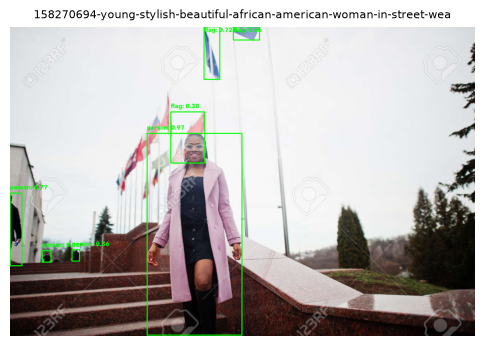

In [2]:
def draw_detections(img, result, names):
    out = img.copy()
    for box, cls, score in zip(result.boxes.xyxy, result.boxes.cls, result.boxes.conf):
        x1, y1, x2, y2 = map(int, box)                                   # box corners in pixels
        label = f"{names[int(cls)]}: {float(score):.2f}"                 # class name + confidence
        cv2.rectangle(out, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(out, label, (x1, max(15, y1 - 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    return out


def show(img, title="", size=6):
    plt.figure(figsize=(size, size))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title, fontsize=8)
    plt.axis("off")
    plt.show()


model = load_yoloe(PROMPTS)
demo = image_paths[5]
result = model.predict(str(demo), conf=CONF, verbose=False)[0]
annotated = draw_detections(cv2.imread(str(demo)), result, model.names)
cv2.imwrite(str(ANNOTATED_DIR / "demo.jpg"), annotated)
show(annotated, demo.name[:70])

## 3. The batch pipeline
Each image is processed one at a time. We keep one row per detection (class, confidence, box, and the box's share of the frame) and save annotated copies of the first few images. This is the slow step, so results are saved and reused.

In [3]:
DET_CSV = OUT_DIR / "ex3_yoloe_detections.csv"

if DET_CSV.exists() and not RERUN:
    det = pd.read_csv(DET_CSV)
    print(f"Loaded {len(det)} saved detections from {DET_CSV.name} (set RERUN = True to recompute)")
else:
    rows = []
    for i, path in enumerate(image_paths):
        r = model.predict(str(path), conf=CONF, verbose=False)[0]
        h, w = r.orig_shape
        rows.append({"image_path": rel(path), "class": None})          # placeholder: every image gets a row
        for box, cls, score in zip(r.boxes.xyxy.tolist(), r.boxes.cls.tolist(), r.boxes.conf.tolist()):
            x1, y1, x2, y2 = box
            rows.append({"image_path": rel(path), "class": model.names[int(cls)], "conf": round(score, 3),
                         "x1": round(x1), "y1": round(y1), "x2": round(x2), "y2": round(y2),
                         "box_area_pct": round((x2 - x1) * (y2 - y1) / (w * h), 4)})
        if i < N_ANNOTATE:
            cv2.imwrite(str(ANNOTATED_DIR / f"{path.stem.split('-')[0]}.jpg"),
                        draw_detections(cv2.imread(str(path)), r, model.names))
        if (i + 1) % 200 == 0:
            print(f"{i + 1}/{len(image_paths)}")
    det = pd.DataFrame(rows)
    det.to_csv(DET_CSV, index=False)
    print(f"Saved {det['class'].notna().sum()} detections to {DET_CSV.name}")

det.dropna(subset=["class"]).head()

200/1797


400/1797


600/1797


800/1797


1000/1797


1200/1797


1400/1797


1600/1797


Saved 5528 detections to ex3_yoloe_detections.csv


,image_path,class,conf,x1,y1,x2,y2,box_area_pct
1,images_123rf/0/00/195392097-pride-lgbtq-and-bl...,person,0.984,228.0,38.0,958.0,864.0,0.5354
2,images_123rf/0/00/195392097-pride-lgbtq-and-bl...,flag,0.598,51.0,159.0,430.0,560.0,0.1346
4,images_123rf/0/00/2874056-a-stunningly-beautif...,person,0.954,234.0,368.0,831.0,1300.0,0.4941
5,images_123rf/0/00/2874056-a-stunningly-beautif...,flag,0.871,315.0,134.0,460.0,454.0,0.0413
6,images_123rf/0/00/2874056-a-stunningly-beautif...,flag,0.730,118.0,309.0,232.0,537.0,0.0229


## 4. What did it find?

n_banner       images with >=1:     2 (0%)   total boxes: 2
n_face_paint   images with >=1:   102 (6%)   total boxes: 102
n_flag         images with >=1:  1178 (66%)   total boxes: 3120
n_person       images with >=1:  1795 (100%)   total boxes: 2304


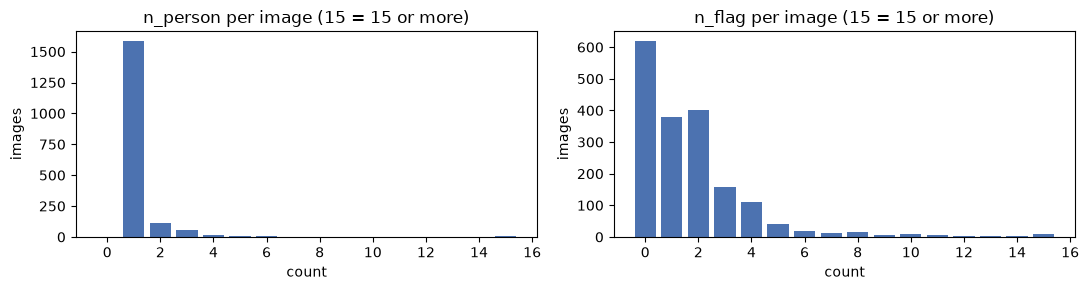

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
banner,2.0,0.27,0.02,0.26,0.26,0.27,0.28,0.28
face paint,102.0,0.41,0.07,0.26,0.35,0.41,0.46,0.56
flag,3120.0,0.57,0.22,0.25,0.37,0.56,0.77,0.98
person,2304.0,0.87,0.18,0.25,0.88,0.96,0.97,0.99


In [4]:
d = det.dropna(subset=["class"])
counts = d.pivot_table(index="image_path", columns="class", values="conf", aggfunc="count", fill_value=0)
per_image = det[["image_path"]].drop_duplicates().set_index("image_path").join(counts).fillna(0).astype(int)
per_image.columns = [f"n_{c.replace(' ', '_')}" for c in per_image.columns]

n = len(per_image)
for c in per_image.columns:
    print(f"{c:14s} images with >=1: {(per_image[c] > 0).sum():5d} ({(per_image[c] > 0).mean():.0%})   "
          f"total boxes: {per_image[c].sum()}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, c in zip(axes, ["n_person", "n_flag"]):
    vc = per_image[c].clip(upper=15).value_counts().sort_index()
    ax.bar(vc.index, vc.values, color="#4C72B0")
    ax.set_title(f"{c} per image (15 = 15 or more)"); ax.set_xlabel("count"); ax.set_ylabel("images")
plt.tight_layout(); plt.show()

d.groupby("class").conf.describe().round(2)

## 5. Cross-check with Exercise 1: how badly does the face detector undercount crowds?
Exercise 1 suspected that MediaPipe's `FaceLandmarker` misses small faces. YOLOe's "person" boxes give an independent count. Note that this compares *people* with *faces*: someone seen from behind is a person with no visible face.

In [5]:
ex1 = pd.read_csv(OUT_DIR / "ex1_faces.csv").drop_duplicates("image_path")[["image_path", "n_faces", "person_pct"]]
joined = per_image.reset_index().merge(ex1, on="image_path", how="left")
joined.to_csv(OUT_DIR / "ex3_yoloe_per_image.csv", index=False)

joined["people_bin"] = pd.cut(joined.n_person, [-1, 0, 1, 2, 4, 9, 1000], labels=["0", "1", "2", "3-4", "5-9", "10+"])
summary = joined.groupby("people_bin", observed=True).agg(
    images=("image_path", "count"),
    mean_faces_found=("n_faces", "mean"),
    share_with_no_face=("n_faces", lambda s: (s == 0).mean()),
).round(2)
summary

,images,mean_faces_found,share_with_no_face
people_bin,,,
0,2,1.00,0.00
1,1585,0.72,0.28
2,111,0.56,0.48
3-4,73,0.58,0.73
5-9,19,0.84,0.42
10+,7,0.00,1.00


15 images with 5+ people (YOLOe) but 0 faces (MediaPipe)


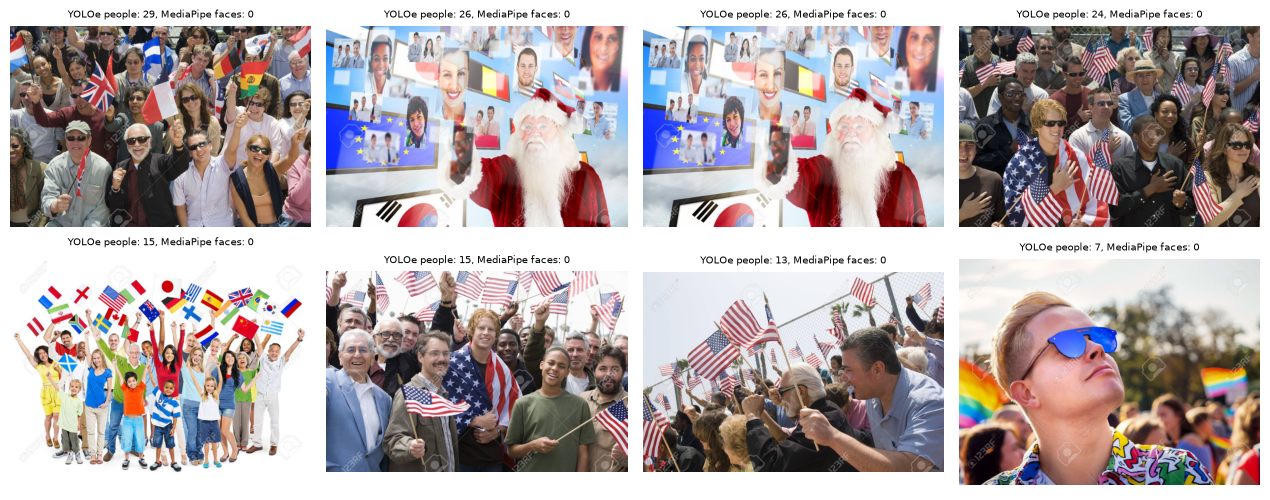

In [6]:
def contact_sheet(paths, titles, cols=4, size=3.2, boxes=None):
    rows_n = math.ceil(len(paths) / cols)
    fig, axes = plt.subplots(rows_n, cols, figsize=(cols * size, rows_n * size * 0.8))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for ax, p, t in zip(np.atleast_1d(axes).ravel(), paths, titles):
        ax.imshow(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB))
        ax.set_title(t, fontsize=7)
    plt.tight_layout(); plt.show()


crowds = joined[(joined.n_person >= 5) & (joined.n_faces == 0)].sort_values("n_person", ascending=False).head(8)
print(f"{((joined.n_person >= 5) & (joined.n_faces == 0)).sum()} images with 5+ people (YOLOe) but 0 faces (MediaPipe)")
contact_sheet([DATA_DIR / p for p in crowds.image_path],
              [f"YOLOe people: {a}, MediaPipe faces: {b}" for a, b in zip(crowds.n_person, crowds.n_faces)])

## 6. Testing the limits of words (300-image subset)
Running YOLOe on every image for every experiment would take hours on a CPU, so we take a fixed **subset**, chosen on purpose using words in the filenames:
- 120 images whose filename names the **USA** ("american", "usa", "stars-and-stripes")
- every image naming **pride/rainbow** (10), **British** (26) or **German** (27) flags
- 120 images that name **no** country

Filenames are written by stock photographers to sell images, so they are a *rough* answer key at best. Note: "usa-states-flags" filenames (the doctor/surgeon series) show **state** flags, not the US flag.

In [7]:
names_lower = pd.Series([p.name.lower() for p in image_paths], index=[rel(p) for p in image_paths])
KEYWORDS = {
    "usa": r"american|usa|stars-and-stripes|united-states",
    "pride": r"pride|rainbow|lgbt",
    "british": r"british|union-jack|england|\buk\b",
    "german": r"german",
}
group = pd.Series("none", index=names_lower.index)
for g, pattern in KEYWORDS.items():
    group[names_lower.str.contains(pattern) & (group == "none")] = g
group[(group == "none") & names_lower.str.contains(r"brazil|canad|franc|ital|spain|spanish|japan|china|chinese|india|mexic|russia|europe")] = "other_country"
# "usa-states-flags" filenames show individual US *state* flags, so they get their own group
group[names_lower.str.contains("states-flags")] = "usa_states"

rng = np.random.default_rng(78000)
picks = []
for g, n_take in [("usa", 120), ("usa_states", 20), ("pride", 99), ("british", 99), ("german", 99), ("none", 120)]:
    members = group.index[group == g]
    picks += list(rng.choice(members, size=min(n_take, len(members)), replace=False))
subset = pd.DataFrame({"image_path": picks, "keyword_group": group[picks].values})
print(subset.keyword_group.value_counts().to_string())


def run_subset(model, tag):
    cache = OUT_DIR / f"ex3_subset_{tag}.csv"
    if cache.exists() and not RERUN:
        return pd.read_csv(cache)
    rows = []
    for p in subset.image_path:
        r = model.predict(str(DATA_DIR / p), conf=CONF, verbose=False)[0]
        rows.append({"image_path": p, "class": None})
        for cls, score in zip(r.boxes.cls.tolist(), r.boxes.conf.tolist()):
            rows.append({"image_path": p, "class": r.names[int(cls)], "conf": round(score, 3)})
    out = pd.DataFrame(rows)
    out.to_csv(cache, index=False)
    return out

keyword_group
usa           120
none          120
usa_states     20
german         19
british        18
pride           8


### 6a. Specific flags
If the text prompts work, "american flag" should fire mostly on the `usa` group, "rainbow flag" on `pride`, and so on. The table shows the **share of images in each filename group** where each prompt fired at least once. Prompts compete: every box gets the single best-matching prompt.

In [8]:
SPECIFIC = ["american flag", "rainbow flag", "british flag", "german flag"]
spec = run_subset(load_yoloe(SPECIFIC), "specific")


def hit_table(results, prompts):
    hits = results.dropna(subset=["class"]).groupby(["image_path", "class"]).size().unstack(fill_value=0) > 0
    hits = subset.set_index("image_path").join(hits).fillna(False)
    return hits.groupby("keyword_group")[[p for p in prompts if p in hits.columns]].mean().round(2)


spec_table = hit_table(spec, SPECIFIC)
spec_table

C:\Users\richa\venvs\data78000\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


,american flag,rainbow flag,british flag,german flag
keyword_group,,,,
british,0.055556,0.555556,0.0,0.333333
german,0.105263,0.210526,0.0,0.578947
none,0.225,0.45,0.025,0.358333
pride,0.0,0.625,0.0,0.0
usa,0.658333,0.366667,0.008333,0.291667
usa_states,0.0,0.0,0.0,0.0


### 6b. Abstract concepts
A detector draws boxes around *things*. What happens when the "thing" is an idea? Any box it draws for "patriotism" shows what the text encoder associates with the word.

In [9]:
ABSTRACT = ["patriotism", "protest", "celebration", "diversity", "freedom"]
abstract = run_subset(load_yoloe(ABSTRACT), "abstract")
a = abstract.dropna(subset=["class"])
print("Boxes per abstract prompt (300 images):")
print(a["class"].value_counts().reindex(ABSTRACT, fill_value=0).to_string())
print()
print(a.groupby("class").conf.agg(["mean", "max"]).round(2))

C:\Users\richa\venvs\data78000\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Boxes per abstract prompt (300 images):
class
patriotism     168
protest         18
celebration      0
diversity        0
freedom          6

            mean   max
class                 
freedom     0.35  0.56
patriotism  0.38  0.87
protest     0.36  0.60


C:\Users\richa\venvs\data78000\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


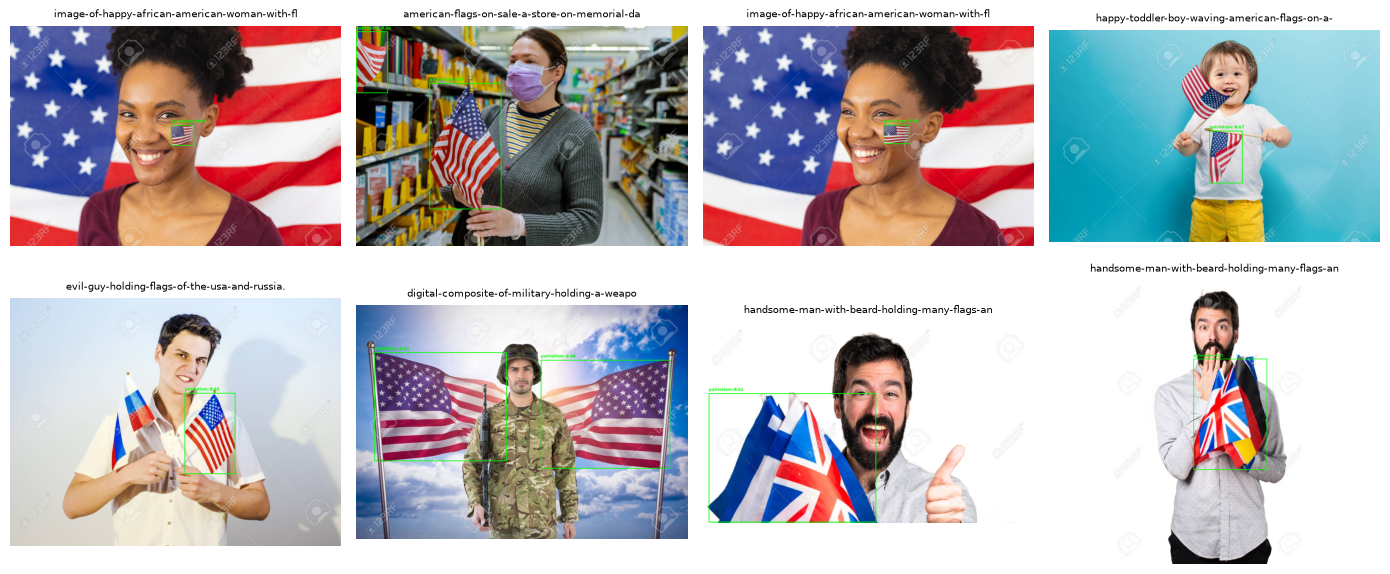

In [10]:
# What do the highest-confidence 'concept' boxes actually contain? Re-run on a few images to draw them.
abstract_model = load_yoloe(ABSTRACT)
top = a.sort_values("conf", ascending=False).drop_duplicates("image_path").head(8)
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax in axes.ravel():
    ax.axis("off")
for ax, p in zip(axes.ravel(), top.image_path):
    r = abstract_model.predict(str(DATA_DIR / p), conf=CONF, verbose=False)[0]
    ax.imshow(cv2.cvtColor(draw_detections(cv2.imread(str(DATA_DIR / p)), r, r.names), cv2.COLOR_BGR2RGB))
    ax.set_title(Path(p).name.split("-", 1)[1][:45], fontsize=7)
plt.tight_layout(); plt.show()

### 6c. Prompt-free: what does YOLOe name on its own?
The `-pf` model has a built-in vocabulary of several thousand everyday object names and no text prompt. Does "flag" come up unprompted, and what else does it see in these photos?

In [11]:
pf = run_subset(load_yoloe(prompt_free=True), "prompt_free")
p = pf.dropna(subset=["class"])
print(f"{p['class'].nunique()} distinct names used across {p.image_path.nunique()} images")
print(f"Images where 'flag' appears unprompted: {p[p['class'] == 'flag'].image_path.nunique()} of {len(subset)}")
p["class"].value_counts().head(25).to_frame("boxes")

492 distinct names used across 305 images
Images where 'flag' appears unprompted: 196 of 305


,boxes
class,
flag,481
person,386
signature,182
heart shape,110
embellishment,105
backdrop,94
glasses,73
letter logo,71
neckband,69


## 7. Reflection

**What worked**
- `person` is reliable: found in 1,795 of 1,797 images, median confidence 0.96.
- `flag` is useful but loose: 66% of images, 3,120 boxes, with confidences spread from 0.25 to 0.98. Small hand-held flags and bunting score low.
- Joining with Exercise 1 quantifies the crowd problem. When YOLOe sees 1 person, MediaPipe finds no face 28% of the time. At 3–4 people that rises to 73%, and at 10+ people it is 100%. The contact sheet shows the faces are plainly visible: MediaPipe's short-range face model, not the photo, is what fails.

**Where it fell short**
- **Pictures inside pictures.** The Santa composite counts 26 "people" because every photo on the video wall counts as a person. Exercise 1 found 0 faces there. Neither number is "right"; it depends what you mean by a person.
- **Specific flags.** `american flag` fires on 66% of `usa` filenames and 0% of the `usa_states` ones (state flags really aren't the US flag, so that's correct). But it also fires on 22% of images with no country keyword. `rainbow flag` fires on 56% of *British* and 37% of *USA* images; it seems to mean "colourful flag". `british flag` almost never fires, not even on the 18 British-keyword images (0%). `german flag` fires on 58% of German images but also on 36% of the no-keyword group. The text encoder knows "flag" well, and countries only vaguely. That is the gap a trained model (Exercise 4) is meant to fill.
- **Abstract prompts.** `patriotism` drew 168 boxes, and the figure shows they all sit on US flags: the concept collapses onto its most common visual symbol. `protest` drew 18 and `freedom` 6, both on flags again. `celebration` and `diversity` drew nothing. A detector can only point at things, so a prompt with no single object behind it either fails silently or quietly turns into a stereotype.
- **Prompt-free model.** Unprompted, it finds `flag` in 196 of 305 images and uses 492 different names. Many are hallucinated or odd for stock photos: `signature` (182, probably the 123RF watermark), `heart shape`, `snowflake`, `seminar`, `stab`, `orbit`, `basketball hoop`. Its vocabulary is huge but not calibrated to this domain.
- `face paint` (102 boxes, max confidence 0.56) and `banner` (2 boxes) are weak; I wouldn't trust either without looking.

**Takeaway:** open-vocabulary detection is great for a first sweep ("is there a flag and a person here?") and for measuring another model's blind spots. But the words you type are not the categories you get. Any claim that relies on prompts finer than "flag" needs a trained model or a human check.